In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [6]:
c_data = pd.read_csv("data.csv",encoding='latin1')
c_data.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [7]:
c_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [8]:
c_data.describe()


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [9]:
c_data.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
c_data = c_data.dropna(subset=['CustomerID'])

In [12]:
c_data.duplicated().sum()

np.int64(5225)

In [13]:
c_data = c_data.drop_duplicates()

The InvoiceDate column is currently stored as an object (string) datatype.

This creates a problem because:

We cannot perform time-based calculations
Recency (for RFM) requires date operations

In [15]:
c_data['InvoiceDate'] = pd.to_datetime(c_data['InvoiceDate'])

In [16]:
c_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  object        
 1   StockCode    401604 non-null  object        
 2   Description  401604 non-null  object        
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[ns]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      401604 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.6+ MB


In [17]:
c_data[c_data['Quantity'] < 0].head()
c_data['Quantity'].min()

-80995

In [18]:
returns_df = c_data[c_data['Quantity'] < 0]

In [51]:
returns_df.to_csv("returns_data.csv", index=False)

## Handling Negative Quantity Values

### Observation
The dataset contains negative values in the Quantity column, with extreme values as low as -80995.

### Interpretation
Negative quantities represent product returns or cancellations. The presence of very large negative values suggests bulk returns or adjustments in transactions.

### Decision
To maintain accurate customer purchase behavior for segmentation, these records will be excluded from the main dataset. However, they can be stored separately for return analysis.

In [19]:
c_data = c_data[c_data['Quantity'] > 0]

In [20]:
c_data['Quantity'].min()

1

## Verification of Quantity Cleaning

### Observation
After removing negative values, the minimum quantity in the dataset is 1.

### Interpretation
This confirms that all remaining transactions represent valid purchases.

### Conclusion
The dataset is now clean and suitable for customer behavior analysis and segmentation.

In [24]:
c_data['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

## Finding Latest Transaction Date

### Observation
The most recent transaction in the dataset occurred on 2011-12-09.

### Interpretation
This represents the last available purchase date in the dataset.

### Conclusion
This date will be used as a reference point to calculate recency for each customer.

In [25]:
max_date = c_data['InvoiceDate'].max()

In [27]:
recency = c_data.groupby('CustomerID')['InvoiceDate'].max()
recency = (max_date - recency).dt.days

## Calculating Recency

For each customer, we find their last purchase date.
Then we calculate how many days have passed since that purchase.

In [28]:
frequency = c_data.groupby('CustomerID')['InvoiceNo'].nunique()

## Calculating Frequency

Frequency represents how many times a customer has made a purchase.
We count the number of unique invoices for each customer.

In [30]:
c_data['TotalPrice'] = c_data['Quantity'] * c_data['UnitPrice']

## Creating Total Price Column

### Observation
The dataset contains Quantity and UnitPrice but does not include total transaction value.

### Approach
A new column 'TotalPrice' is created by multiplying Quantity and UnitPrice.

### Purpose
This helps in calculating the total amount spent by each customer, which is required for Monetary analysis in RFM.

In [31]:
monetary = c_data.groupby('CustomerID')['TotalPrice'].sum()

In [32]:
rfm = pd.DataFrame({
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,1,7,4310.00
12348.0,74,4,1797.24
12349.0,18,1,1757.55
12350.0,309,1,334.40


## RFM Table Overview

### Description
The RFM table contains customer-level metrics:

- Recency: Days since last purchase
- Frequency: Number of purchases
- Monetary: Total amount spent

### Interpretation
This table helps in understanding customer behavior:

- Low Recency + High Frequency + High Monetary → High-value customers
- High Recency + Low Frequency + Low Monetary → Low-value or inactive customers

### Conclusion
RFM features will be used for customer segmentation using clustering.

In [33]:
rfm.describe()

,Recency,Frequency,Monetary
count,4339.000000,4339.000000,4339.000000
mean,91.518322,4.271952,2048.215924
std,100.009747,7.705493,8984.248352
min,0.000000,1.000000,0.000000
25%,17.000000,1.000000,306.455000
50%,50.000000,2.000000,668.560000
75%,141.000000,5.000000,1660.315000
max,373.000000,210.000000,280206.020000


## RFM Distribution Analysis

### Observation
The RFM variables show significant variation across customers:

- Monetary values are highly skewed, with a few customers contributing very high revenue.
- Frequency shows that most customers purchase infrequently, while a few are highly active.
- Recency varies widely, indicating both recent and inactive customers.

### Interpretation
This indicates the presence of different customer segments such as:
- High-value customers
- Frequent buyers
- Inactive customers

### Conclusion
Since the features have different scales and distributions, scaling is required before applying clustering.

In [34]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

In [35]:
rfm_scaled = pd.DataFrame(rfm_scaled, columns=rfm.columns)
rfm_scaled.head()

,Recency,Frequency,Monetary
0,2.334858,-0.424675,8.363977
1,-0.905199,0.354080,0.251779
2,-0.175186,-0.035297,-0.027938
3,-0.735196,-0.424675,-0.032357
4,2.174855,-0.424675,-0.190780


## Feature Scaling

### Problem
RFM features have different scales:
- Monetary values are much higher than Recency and Frequency

### Solution
StandardScaler is used to normalize the data so that all features contribute equally.

### Outcome
The scaled dataset ensures that no single feature dominates the clustering process.

In [37]:
inertia = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

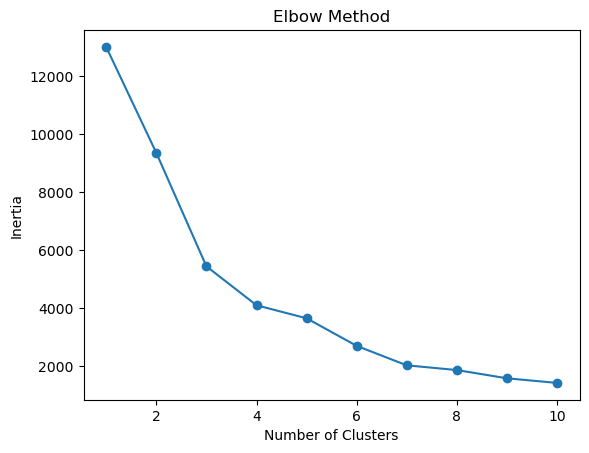

In [38]:
plt.plot(range(1, 11), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

## Choosing Number of Clusters

### Observation
The Elbow graph shows a sharp decrease in inertia up to 3–4 clusters, after which the curve starts to flatten.

### Interpretation
This indicates that adding more clusters beyond this point does not significantly improve model performance.

### Conclusion
4 clusters were selected as the optimal number, as it provides a good balance between model performance and interpretability.

In [39]:
kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

In [40]:
rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,325,1,77183.60,0
12347.0,1,7,4310.00,3
12348.0,74,4,1797.24,3
12349.0,18,1,1757.55,3
12350.0,309,1,334.40,1


## Applying K-Means Clustering

### Approach
K-Means clustering is applied with 4 clusters to segment customers based on RFM features.

### Outcome
Each customer is assigned to a cluster representing similar purchasing behavior.

In [41]:
rfm.groupby('Cluster').mean()

,Recency,Frequency,Monetary
Cluster,,,
0,14.672986,22.047393,12435.086682
1,247.564030,1.551789,476.330547
2,6.384615,82.692308,127187.959231
3,42.910580,3.655748,1344.284013


## Cluster Interpretation

### Approach
Customers are grouped based on Recency, Frequency, and Monetary values.

## Final Customer Segmentation

Based on RFM analysis and clustering, the following customer segments were identified:

- Cluster 2: VIP Customers  
  These customers have very recent purchases, extremely high frequency, and the highest spending.

- Cluster 0: Loyal Customers  
  These customers purchase frequently and contribute significant revenue.

- Cluster 3: At-Risk Customers  
  These customers have moderate purchase history but have not purchased recently.

- Cluster 1: Low-Value Customers  
  These customers have low frequency, low spending, and have not purchased in a long time.

### Conclusion
The segmentation helps businesses identify high-value customers, retain at-risk users, and target low-value customers for engagement strategies.

In [42]:
rfm['Segment'] = rfm['Cluster'].map({
    2: 'VIP Customers',
    0: 'Loyal Customers',
    3: 'At Risk Customers',
    1: 'Low Value Customers'
})
rfm.head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346.0,325,1,77183.60,0,Loyal Customers
12347.0,1,7,4310.00,3,At Risk Customers
12348.0,74,4,1797.24,3,At Risk Customers
12349.0,18,1,1757.55,3,At Risk Customers
12350.0,309,1,334.40,1,Low Value Customers


In [53]:
rfm.to_csv("rfm_data.csv")

## Business Impact

The customer segmentation model provides actionable insights that can significantly improve business performance:

- Helps identify high-value customers for targeted retention and upselling, increasing revenue.
- Enables early detection of at-risk customers, allowing proactive retention strategies.
- Supports personalized marketing, improving conversion rates and customer engagement.
- Optimizes marketing spend by focusing on the most valuable customer segments.
- Assists in data-driven decision-making for product and business strategy.

Overall, this project helps businesses improve customer retention, increase revenue, and enhance operational efficiency.

1- REVENUE GROWTH
I identified:VIP customer,Loyal customers
Business can:Give exclusive offers,Launch premium products
Result:Increase revenue from high-value customers

2-Customer Retention 
I identified:At-risk customers
Business can:Send discounts,Re-engagement emails,Personalized offers
Result:Prevent customer churn

3- Targeted Marketing
Instead of Same ad to everyone
Now:Different strategy for each segment 
Example:VIP → premium offers
Low-value → discounts
Frequent → loyalty rewards
Result:Better conversion rate

4- Cost Optimization Without segmentation Marketing spend wasted With segmentation Spend only on right customers 
Result:Higher ROI

5- Business Decision Making 
Your insights:
Who generates revenue
Who is inactive
Who is growing
Helps:
Product decisions
Pricing strategies
Campaign planning

In [52]:
c_data.to_csv("cleaned_data.csv", index=False)

## Analysis: Returns Behavior
Negative quantities represent product returns. 
Instead of discarding them, a separate dataset was created to analyze return patterns.

In [44]:
returns_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [45]:
returns_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8872 entries, 141 to 541717
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    8872 non-null   object        
 1   StockCode    8872 non-null   object        
 2   Description  8872 non-null   object        
 3   Quantity     8872 non-null   int64         
 4   InvoiceDate  8872 non-null   datetime64[ns]
 5   UnitPrice    8872 non-null   float64       
 6   CustomerID   8872 non-null   float64       
 7   Country      8872 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 623.8+ KB


In [46]:
## top returned product

In [47]:
returns_df['Description'].value_counts().head(10)

Description
REGENCY CAKESTAND 3 TIER             180
Manual                               175
POSTAGE                               97
JAM MAKING SET WITH JARS              86
Discount                              77
SET OF 3 CAKE TINS PANTRY DESIGN      72
STRAWBERRY CERAMIC TRINKET BOX        54
ROSES REGENCY TEACUP AND SAUCER       53
RECIPE BOX PANTRY YELLOW DESIGN       47
JUMBO BAG RED RETROSPOT               44
Name: count, dtype: int64

In [49]:
#Create TotalPrice for returns
returns_df['TotalPrice'] = returns_df['Quantity'] * returns_df['UnitPrice']

In [50]:
#Total Loss due to Returns
returns_df['TotalPrice'].sum()

np.float64(-608689.47)

In [48]:
## return by country
returns_df['Country'].value_counts().head(10)

Country
United Kingdom    7501
Germany            453
EIRE               247
France             148
USA                112
Australia           74
Spain               48
Italy               45
Belgium             38
Japan               37
Name: count, dtype: int64

## Returns Analysis

### Key Insights

- Returns contribute to revenue loss as indicated by negative transaction values.
- Certain products show higher return frequency, indicating possible quality or expectation issues.
- Return patterns vary across countries, suggesting potential regional differences in customer behavior or logistics.

### Business Impact

- Helps identify problematic products and improve quality
- Reduces revenue loss by addressing return causes
- Improves customer satisfaction through better product alignment